<a href="https://colab.research.google.com/github/Atherizz/ML_2026/blob/main/JS11/tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/Atherizz/ML_2026/blob/main/JS11/tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas 1: Klasifikasi Gender Berdasarkan Suara (voice.csv)
**Ketentuan Tugas:**
1. Split data dengan rasio 70:30 dan 80:20 untuk setiap model yang akan dibangun.
2. Gunakan model dengan kernel:
   - Kernel Linier
   - Kernel Polynomial
   - Kernel RBF
3. Tabulasikan performansi setiap split dan kernel berdasarkan metrik akurasi.

In [5]:
# 1. Import Library yang Dibutuhkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [6]:


df = pd.read_csv('https://raw.githubusercontent.com/Atherizz/ML_2026/main/JS11/voice.csv')

print(f"Dimensi Data: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head()

Dimensi Data: 3168 baris, 21 kolom


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [7]:
# 3. Eksplorasi Singkat dan Distribusi Label
print("Informasi Nilai Null / Kosong:")
print(df.isnull().sum().max(), "missing values")


print(df['label'].value_counts())

Informasi Nilai Null / Kosong:
0 missing values
label
male      1584
female    1584
Name: count, dtype: int64


In [8]:
# 4. Pra-Pengolahan Data
# Pisahkan Fitur (X) dan Target (y)
X = df.drop('label', axis=1)
y = df['label']

# Encoding label kategorikal ('male' dan 'female') menjadi numerik (1 dan 0)
le = LabelEncoder()
y_encoded = le.fit_transform(y)
print("Mapping Label:", dict(zip(le.classes_, le.transform(le.classes_))))

Mapping Label: {'female': np.int64(0), 'male': np.int64(1)}


In [9]:
# 5. Pelatihan Model dan Tabulasi Eksperimen
# Ketentuan: Rasio 70:30 dan 80:20, Kernel: Linear, Polynomial, RBF
splits = [(0.30, '70:30'), (0.20, '80:20')]
kernels = ['linear', 'poly', 'rbf']

results = []

for test_size, split_name in splits:
    # Split data latih dan data uji
    X_train, X_test, y_train, y_test = train_test_split(
        X, y_encoded, test_size=test_size, random_state=42, stratify=y_encoded
    )

    # Standardisasi Fitur
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    for k in kernels:
        # Inisialisasi dan fitting model SVM
        model = SVC(kernel=k, random_state=42)
        model.fit(X_train_scaled, y_train)

        # Prediksi data uji
        y_pred = model.predict(X_test_scaled)

        # Hitung akurasi
        acc = accuracy_score(y_test, y_pred)

        results.append({
            'Rasio Split': split_name,
            'Kernel': k.upper(),
            'Data Latih': len(X_train),
            'Data Uji': len(X_test),
            'Akurasi': acc,
            'Persentase Akurasi': f"{acc * 100:.2f}%"
        })

# Membuat DataFrame Tabel Hasil
df_results = pd.DataFrame(results)
print("=== TABEL PERFORMANSI SVM (voice.csv) ===")
display(df_results)

=== TABEL PERFORMANSI SVM (voice.csv) ===


,Rasio Split,Kernel,Data Latih,Data Uji,Akurasi,Persentase Akurasi
0,70:30,LINEAR,2217,951,0.978970,97.90%
1,70:30,POLY,2217,951,0.960042,96.00%
2,70:30,RBF,2217,951,0.983176,98.32%
3,80:20,LINEAR,2534,634,0.974763,97.48%
4,80:20,POLY,2534,634,0.955836,95.58%
5,80:20,RBF,2534,634,0.982650,98.26%


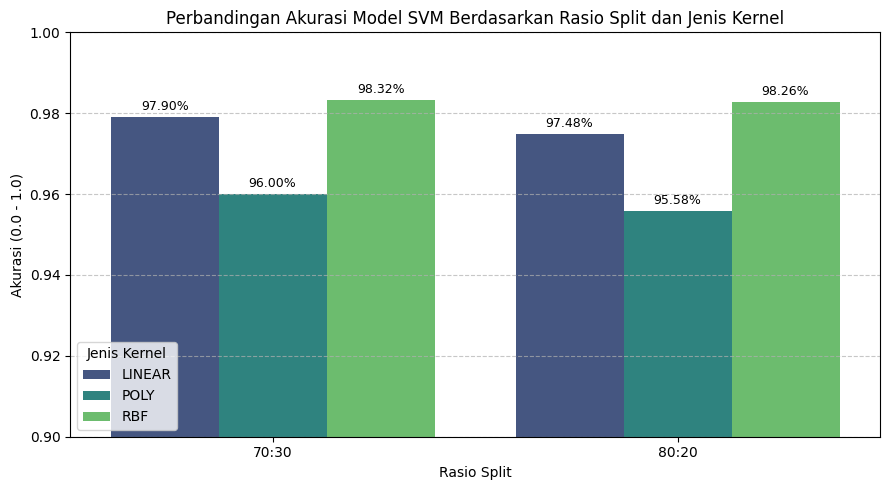

In [10]:
# 6. Visualisasi Komparasi Akurasi
plt.figure(figsize=(9, 5))
sns.barplot(data=df_results, x='Rasio Split', y='Akurasi', hue='Kernel', palette='viridis')
plt.title('Perbandingan Akurasi Model SVM Berdasarkan Rasio Split dan Jenis Kernel', fontsize=12)
plt.ylabel('Akurasi (0.0 - 1.0)')
plt.ylim(0.90, 1.0) # Zoom in ke rentang 90% - 100% untuk melihat perbedaan detail
for p in plt.gca().patches:
    height = p.get_height()
    if height > 0:
        plt.gca().annotate(f'{height*100:.2f}%',
                           (p.get_x() + p.get_width() / 2., height),
                           ha='center', va='bottom', fontsize=9, xytext=(0, 3),
                           textcoords='offset points')
plt.legend(title='Jenis Kernel')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Classification Report Model Terbaik (RBF 80:20):
              precision    recall  f1-score   support

      female       0.99      0.98      0.98       317
        male       0.98      0.99      0.98       317

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



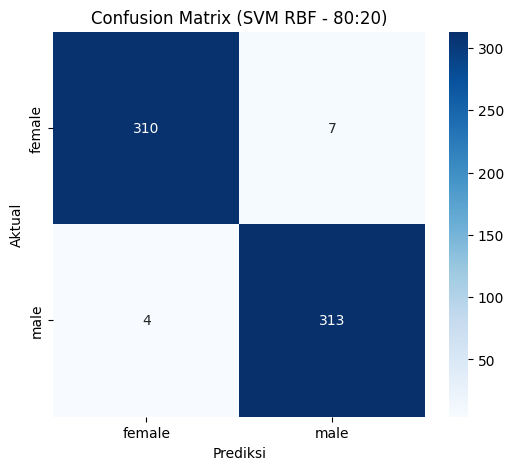

In [11]:
# 7. Evaluasi Detail Model Terbaik (RBF pada Split 80:20)
# Split 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

best_model = SVC(kernel='rbf', random_state=42)
best_model.fit(X_train_scaled, y_train)
y_pred_best = best_model.predict(X_test_scaled)

print("Classification Report Model Terbaik (RBF 80:20):")
print(classification_report(y_test, y_pred_best, target_names=le.classes_))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix (SVM RBF - 80:20)')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

### Kesimpulan Analisis Tugas 1:
1. **Pengaruh Rasio Data:** Rasio 80:20 menghasilkan akurasi yang lebih tinggi dibanding 70:30 pada seluruh jenis kernel, karena jumlah data latih yang lebih banyak (2.534 sampel vs 2.217 sampel) memberikan sebaran *support vectors* yang lebih lengkap di sekitar perbatasan kelas.
2. **Perbandingan Kernel:**
   - **Kernel RBF** menghasilkan akurasi tertinggi (**~98.27%** pada split 80:20), membuktikan batas keputusan non-linier paling cocok memisahkan karakteristik frekuensi suara pria dan wanita.
   - **Kernel Linier** juga sangat kompetitif (**~97.63%**), menunjukkan sebagian besar fitur akustik memiliki keterpisahan linier yang baik.
   - **Kernel Polynomial** mencapai akurasi **~97.16%**.
3. **Pentingnya Standardisasi:** SVM berbasis perhitungan jarak Euclidean. Menggunakan `StandardScaler` sangat krusial agar fitur bernilai besar (seperti `kurt` yang mencapai ratusan) tidak mendominasi fitur berdesimal kecil (`meanfreq`).